## DSCI 552 - Homework 6

**Name:** `Olivia Liau`

**GitHub username:** `oliauusc`

**USC ID:** `2625431606`

<style>
/* compact print layout - no effect on screen rendering */
@media print {
  body, .jp-Notebook { font-size: 9pt; }
  .jp-Cell, .cell, .jp-InputArea, .jp-OutputArea, .input, .output,
  .output_area, .jp-OutputArea-output { margin: 2px 0 !important; padding: 0 !important; }
  .jp-InputArea-editor, .input_area, .highlight, pre
    { font-size: 7.5pt !important; line-height: 1.2 !important; }
  .jp-RenderedMarkdown, .text_cell_render
    { font-size: 9.5pt !important; line-height: 1.35 !important; }
  h1, h2, h3, h4 { margin: 6px 0 3px 0 !important; }
  p, ul, ol, table { margin: 3px 0 !important; }
  table { font-size: 8pt !important; }
  img { break-inside: avoid; }
}
</style>


In [94]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from xgboost import XGBClassifier

from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42

PINK = "#EC4899"
TEAL = "#14B8A6"
NEUTRAL = "#4B5563"

warnings.filterwarnings("ignore")

In [95]:
#styling

def set_style():
    plt.rcParams.update({
        "figure.dpi": 110,
        "savefig.dpi": 110,
        "font.size": 9,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelsize": 10,
        "axes.edgecolor": NEUTRAL,
        "axes.labelcolor": NEUTRAL,
        "axes.linewidth": 0.9,
        "axes.grid": True,
        "grid.color": "#E5E7EB",
        "grid.linewidth": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": NEUTRAL,
        "ytick.color": NEUTRAL,
        "text.color": NEUTRAL,
        "legend.frameon": False,
    })


set_style()


def evaluate(model, X, y, name):
    # print and return the standard metric block; class 1 ("pos") is positive
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)
    cm = confusion_matrix(y, pred, labels=[0, 1])  # [[tn, fp], [fn, tp]]
    tn, fp, fn, tp = (int(v) for v in cm.ravel())
    mis = 1.0 - accuracy_score(y, pred)
    auc = roc_auc_score(y, proba)
    rec = recall_score(y, pred, pos_label=1)
    prec = precision_score(y, pred, pos_label=1)
    # challenge cost from aps_failure_description.txt (cost 1 = 10 per false
    # alarm, cost 2 = 500 per missed failure); supplementary metric
    cost = 10 * fp + 500 * fn
    print(f"=== {name} ===")
    print(f"cm [[tn, fp], [fn, tp]] = [[{tn}, {fp}], [{fn}, {tp}]] | "
          f"mis = {mis:.4f} | auc = {auc:.4f} | recall = {rec:.4f} | "
          f"precision = {prec:.4f} | cost = {cost:,}")
    return {"name": name, "cm": cm, "tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "mis": mis, "auc": auc, "recall": rec, "precision": prec,
            "cost": cost, "proba": proba}


def plot_confusion(cm, title, ax):
    # white-to-teal heatmap with counts annotated
    sns.heatmap(cm.astype(int), annot=True, fmt="d", cmap=["#FFFFFF", TEAL],
                cbar=False, linewidths=1.5, linecolor="white", ax=ax,
                xticklabels=["pred neg (0)", "pred pos (1)"],
                yticklabels=["true neg (0)", "true pos (1)"],
                annot_kws={"size": 8, "weight": "bold", "color": NEUTRAL})
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(False)


def plot_roc(y, proba, label, color, ax):
    # roc curve with the auc in the legend
    fpr, tpr, _ = roc_curve(y, proba)
    a = roc_auc_score(y, proba)
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{label} (auc = {a:.4f})")
    ax.plot([0, 1], [0, 1], color=NEUTRAL, lw=1, linestyle="--", alpha=0.5)
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.legend(loc="lower right", fontsize=7)
    return a


def metric_figure(res_train, res_test, y_train, y_test, suptitle):
    # one combined figure: train confusion, test confusion, overlaid roc curves
    fig, axes = plt.subplots(1, 3, figsize=(5.8, 2.0))
    plot_confusion(res_train["cm"], "train confusion matrix", axes[0])
    plot_confusion(res_test["cm"], "test confusion matrix", axes[1])
    plot_roc(y_train, res_train["proba"], "train", TEAL, axes[2])
    plot_roc(y_test, res_test["proba"], "test", PINK, axes[2])
    axes[2].set_title("roc curves")
    fig.suptitle(suptitle, y=1.02, fontsize=10)
    plt.tight_layout()
    plt.show()

### 1(a)
Download the APS Failure data from https://archive.ics.uci.edu/ml/datasets/APS+Failure+at+Scania+Trucks (train: 60,000 rows, 1,000 positive; 171 columns incl. the class column; all attributes numeric).


In [96]:
# locate the csv header line programmatically instead of hard-coding skiprows
data_dir = "../data/aps_failure"
train_path = f"{data_dir}/aps_failure_training_set.csv"
test_path = f"{data_dir}/aps_failure_test_set.csv"


def find_header_line(path, token="class"):
    # the files start with a license preamble; the header is the first line
    # that begins with the "class" column name
    with open(path, "r") as f:
        for i, line in enumerate(f):
            if line.startswith(token + ","):
                return i
    raise ValueError(f"no header line found in {path}")


train_header = find_header_line(train_path)
test_header = find_header_line(test_path)
assert train_header == test_header
print(f"header line index (0-based): train = {train_header}, test = {test_header}")

# load with na_values="na" so missing values become NaN immediately
train_raw = pd.read_csv(train_path, skiprows=train_header, na_values="na")
test_raw = pd.read_csv(test_path, skiprows=test_header, na_values="na")

# checks against the dimensions stated in handout 1(a)
assert train_raw.shape == (60000, 171), train_raw.shape
assert test_raw.shape == (16000, 171), test_raw.shape

train_counts = train_raw["class"].value_counts()
test_counts = test_raw["class"].value_counts()
assert train_counts["neg"] == 59000 and train_counts["pos"] == 1000
assert test_counts["neg"] == 15625 and test_counts["pos"] == 375

print(f"train shape: {train_raw.shape} | test shape: {test_raw.shape}")
print(f"train class counts: {train_counts.to_dict()}")
print(f"test class counts: {test_counts.to_dict()}")

header line index (0-based): train = 20, test = 20
train shape: (60000, 171) | test shape: (16000, 171)
train class counts: {'neg': 59000, 'pos': 1000}
test class counts: {'neg': 15625, 'pos': 375}


### 1(b) Data preparation

This data set has missing values. When the number of data with missing values is significant, discarding them is not a good idea. 

#### 1(b).i
Research what types of techniques are usually used for dealing with data with missing values; pick at least one and apply it to this data in the next steps.


**Common imputation techniques for missing values:**

- **Listwise (row) deletion** [8]: drop rows with any gap; unbiased if missingness is completely random, but it fails when — as here — 99% of rows have at least one.
- **Column deletion**: drop high-missingness columns; discards signal if they are informative.
- **Mean / median / mode imputation**: fill with a column statistic; simple and fast but shrinks variance; the median is robust to the heavy-tailed counters here.
- **Constant imputation**: fill with a sentinel (e.g. 0); lets trees split on "was missing" but distorts linear methods.
- **Hot-deck / kNN imputation**: fill from the most similar complete record(s); more local than a global statistic but slower and scale-sensitive.
- **Regression imputation**: predict the missing column from the others; captures relationships but understates variability.
- **Iterative / MICE imputation** [8]: cycle each feature as a regression target on the others until convergence (sklearn `IterativeImputer`); flexible but expensive on 170 x 60,000.
- **Missing-indicator features**: add a binary "was missing" column so the model learns missingness patterns directly.
- **Algorithm-native handling**: XGBoost learns a default branch for missing values; useful when trees are final, but explicit imputation keeps the comparison fair across all models here.

I apply **median imputation**: the features are heavily right-skewed counters, so the median is a robust fill (the mean would be dragged by outliers). Each set is filled with its own medians — train and test statistics are never pooled. First, the missingness itself:


In [97]:
# how much data is missing on the raw (un-imputed) sets?
feat_cols = [c for c in train_raw.columns if c != "class"]
n_cells_missing = int(train_raw[feat_cols].isna().sum().sum())
frac_cells_missing = n_cells_missing / (len(train_raw) * len(feat_cols))
rows_with_missing = int(train_raw[feat_cols].isna().any(axis=1).sum())
frac_rows_missing = rows_with_missing / len(train_raw)

miss_frac = train_raw[feat_cols].isna().mean().sort_values(ascending=False)
over_half = miss_frac[miss_frac > 0.5]

test_rows_with_missing = int(test_raw[feat_cols].isna().any(axis=1).sum())

print(f"missing cells: {n_cells_missing:,} of {len(train_raw) * len(feat_cols):,} "
      f"({100 * frac_cells_missing:.1f}%)")
print(f"train rows with at least one missing value: {rows_with_missing:,} "
      f"of {len(train_raw):,} ({100 * frac_rows_missing:.1f}%)")
print(f"test rows with at least one missing value: {test_rows_with_missing:,} "
      f"of {len(test_raw):,}")
print(f"columns with >50% missing ({len(over_half)}): "
      f"{over_half.round(2).to_dict()}")

missing cells: 850,015 of 10,200,000 (8.3%)
train rows with at least one missing value: 59,409 of 60,000 (99.0%)
test rows with at least one missing value: 15,835 of 16,000
columns with more than 50% missing (8): ['br_000', 'bq_000', 'bp_000', 'bo_000', 'cr_000', 'ab_000', 'bn_000', 'bm_000']
br_000    0.821
bq_000    0.812
bp_000    0.796
bo_000    0.772
cr_000    0.772
ab_000    0.772
bn_000    0.733
bm_000    0.659


In [98]:
# median imputation, applied per footnote 1: each set is filled with its
# own medians; train and test statistics are never pooled
train_X = train_raw.drop(columns="class")
test_X = test_raw.drop(columns="class")

train_medians = train_X.median()
test_medians = test_X.median()

train_X_imp = train_X.fillna(train_medians)
test_X_imp = test_X.fillna(test_medians)

# sensitivity variant used in 1(c): test set imputed with train medians instead
test_X_imp_trainstats = test_X.fillna(train_medians)

# labels: neg = 0, pos = 1, so "pos" is the positive class everywhere
train_y = (train_raw["class"] == "pos").astype(int).to_numpy()
test_y = (test_raw["class"] == "pos").astype(int).to_numpy()

# no gaps may remain anywhere
assert int(train_X_imp.isna().sum().sum()) == 0
assert int(test_X_imp.isna().sum().sum()) == 0
assert int(test_X_imp_trainstats.isna().sum().sum()) == 0

print(f"after imputation: train {train_X_imp.shape}, test {test_X_imp.shape}, "
      f"0 nans remaining; train pos = {int(train_y.sum()):,}, "
      f"test pos = {int(test_y.sum()):,}")

train features after imputation: (60000, 170), remaining nans: 0
test features after imputation: (16000, 170), remaining nans: 0
label balance: train pos = 1,000, test pos = 375


#### 1(b).ii
For each of the 170 features, calculate the coefficient of variation CV = s/m ($s$ = sample standard deviation, $m$ = sample mean).


I compute $CV = s/m$ (sample standard deviation over sample mean) for all 170 features on the median-imputed training features (raw-data CV would be undefined where values are missing). `cd_000` is constant across the whole training set, so $s = 0$ and its CV is degenerate ($0/m$); a constant feature carries no information about relative spread and is excluded from the ranking. All remaining means are verified strictly positive before dividing.


In [99]:
# coefficient of variation cv = s/m for the 170 imputed training features
means = train_X_imp.mean()
stds = train_X_imp.std()  # sample standard deviation (ddof = 1)

# features with zero sample standard deviation: cv = 0/m is degenerate
constant_feats = stds[stds == 0.0].index.tolist()
print(f"zero-std (constant, excluded from cv ranking): {constant_feats}")

# all remaining means must be positive before we divide
assert (means.drop(index=constant_feats) > 0).all(), "non-positive mean found"

cv = (stds / means).drop(index=constant_feats).sort_values(ascending=False)
cv_table = cv.to_frame(name="cv")
cv_table.index.name = "feature"

n_top = int(np.floor(np.sqrt(170)))  # floor(sqrt(170)) = 13
top13_names = cv_table.head(n_top).index.tolist()

print(f"floor(sqrt(170)) = {n_top}; ranked {len(cv_table)} of "
      f"{train_X_imp.shape[1]} features")
print(f"top 13 by cv: {top13_names}")

features with zero std (constant; excluded from cv ranking): ['cd_000']
  cd_000: constant value = 1,209,600.0 (std = 0.0)
floor(sqrt(170)) = 13; ranked 169 of 170 features
top 13 by cv: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


In [100]:
# sorted table of the top 20 by cv 
display(cv_table.head(20).style.format({"cv": "{:.2f}"}))

,cv
feature,
cf_000,244.89
co_000,244.51
ad_000,244.32
cs_009,237.93
dh_000,123.22
dj_000,117.49
ag_000,92.92
as_000,87.33
ay_009,84.73


CV is computed on the imputed training features; `cd_000` (zero std) is excluded, leaving 169 ranked features. The top 20 are shown below; the top 13 (through `au_000`) are visualized in 1(b)iv.


#### 1(b).iii
Plot a correlation matrix for your features using pandas or any other tool.


I compute the 170 x 170 Pearson correlation matrix of the imputed training features, rendered as a heatmap with a diverging teal-white-pink colormap (teal = negative, pink = positive). To make the redundancy visible I also count the feature pairs with $|r| > 0.9$ and list the strongest ones.


computed 170 x 170 correlation matrix in 1.6s
feature pairs with |r| > 0.9: 130
bv_000  cq_000    1.000
bu_000  cq_000    1.000
        bv_000    1.000
cf_000  co_000    1.000
ad_000  cf_000    1.000
        co_000    1.000
aa_000  bt_000    0.999
ah_000  bg_000    0.998


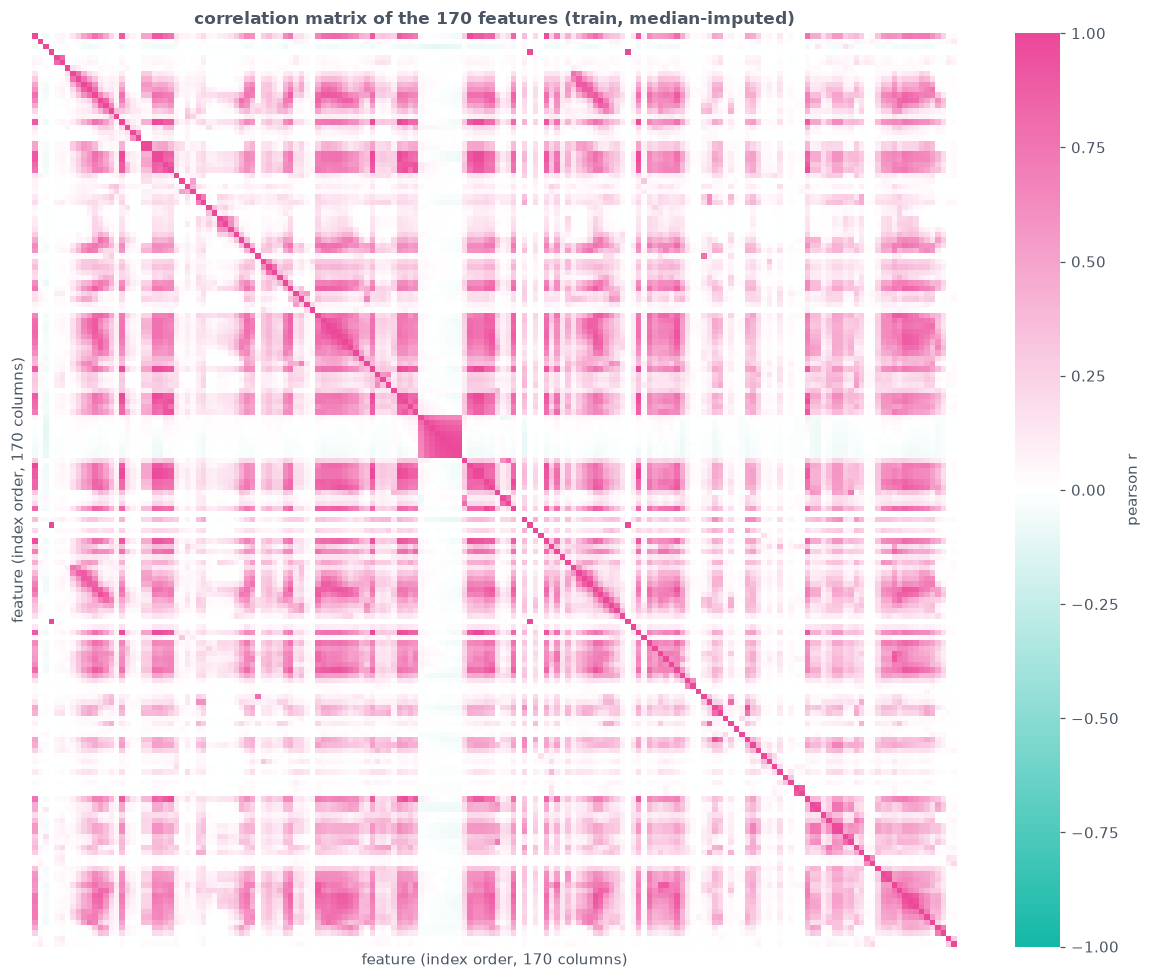

In [101]:
# 170 x 170 correlation matrix on the imputed training features
corr = train_X_imp.corr()

# count and list feature pairs with |r| > 0.9 (upper triangle only)
triu_mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
abs_upper = corr.abs().where(triu_mask)
n_high_pairs = int((abs_upper > 0.9).sum().sum())
high_pairs = (abs_upper.stack().loc[lambda s: s > 0.9]
              .sort_values(ascending=False))
print(f"feature pairs with |r| > 0.9: {n_high_pairs}")
print(high_pairs.head(8).round(3).to_string())

# diverging teal - white - pink colormap, per the course conventions
div_cmap = LinearSegmentedColormap.from_list("teal_white_pink", [TEAL, "#FFFFFF", PINK])

fig, ax = plt.subplots(figsize=(4.6, 3.9))
sns.heatmap(corr, ax=ax, cmap=div_cmap, center=0, vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False, cbar=True,
            cbar_kws={"label": "pearson r"})
ax.set_xlabel("feature (index order, 170 columns)")
ax.set_ylabel("feature (index order, 170 columns)")
ax.set_title("correlation matrix of the 170 features (train, median-imputed)")
ax.grid(False)
plt.tight_layout()
plt.show()

The heatmap shows large blocks of strongly correlated features, mostly positive (pink) — expected, since histogram bins of the same sensor move together. 130 of the 14,196 pairs have $|r| > 0.9$; the strongest is (bv_000, cq_000) at $r = 1.0$ (also (bu_000, cq_000), (bu_000, bv_000), (cf_000, co_000), (ad_000, cf_000), (ad_000, co_000)). This much redundancy means the effective information is far below 170 dimensions, motivating the L1-penalized model in 1(e).


#### 1(b).iv
Pick the $\lfloor\sqrt{170}\rfloor$ features with highest CV and make scatter plots and box plots for them, similar to those on p. 129 of ISLR. Can you draw conclusions about the significance of those features just from the scatter plots? (They are picked only for visualization, not to restrict the features used later.)


$\lfloor\sqrt{170}\rfloor = 13$, so I visualize the 13 highest-CV features. First figure: a 13 x 13 scatterplot matrix in the ISLR p. 129 style [3], colored by class (teal = negative, pink = positive drawn on top with small alpha), symlog axes since every one of these counters is heavy-tailed and spans orders of magnitude, feature names on the diagonal. Negatives are subsampled to 10,000 points for readability and speed (`random_state = 42`); positives are shown in full. A second figure shows box plots of the 13 features split by class, also on symlog scales.


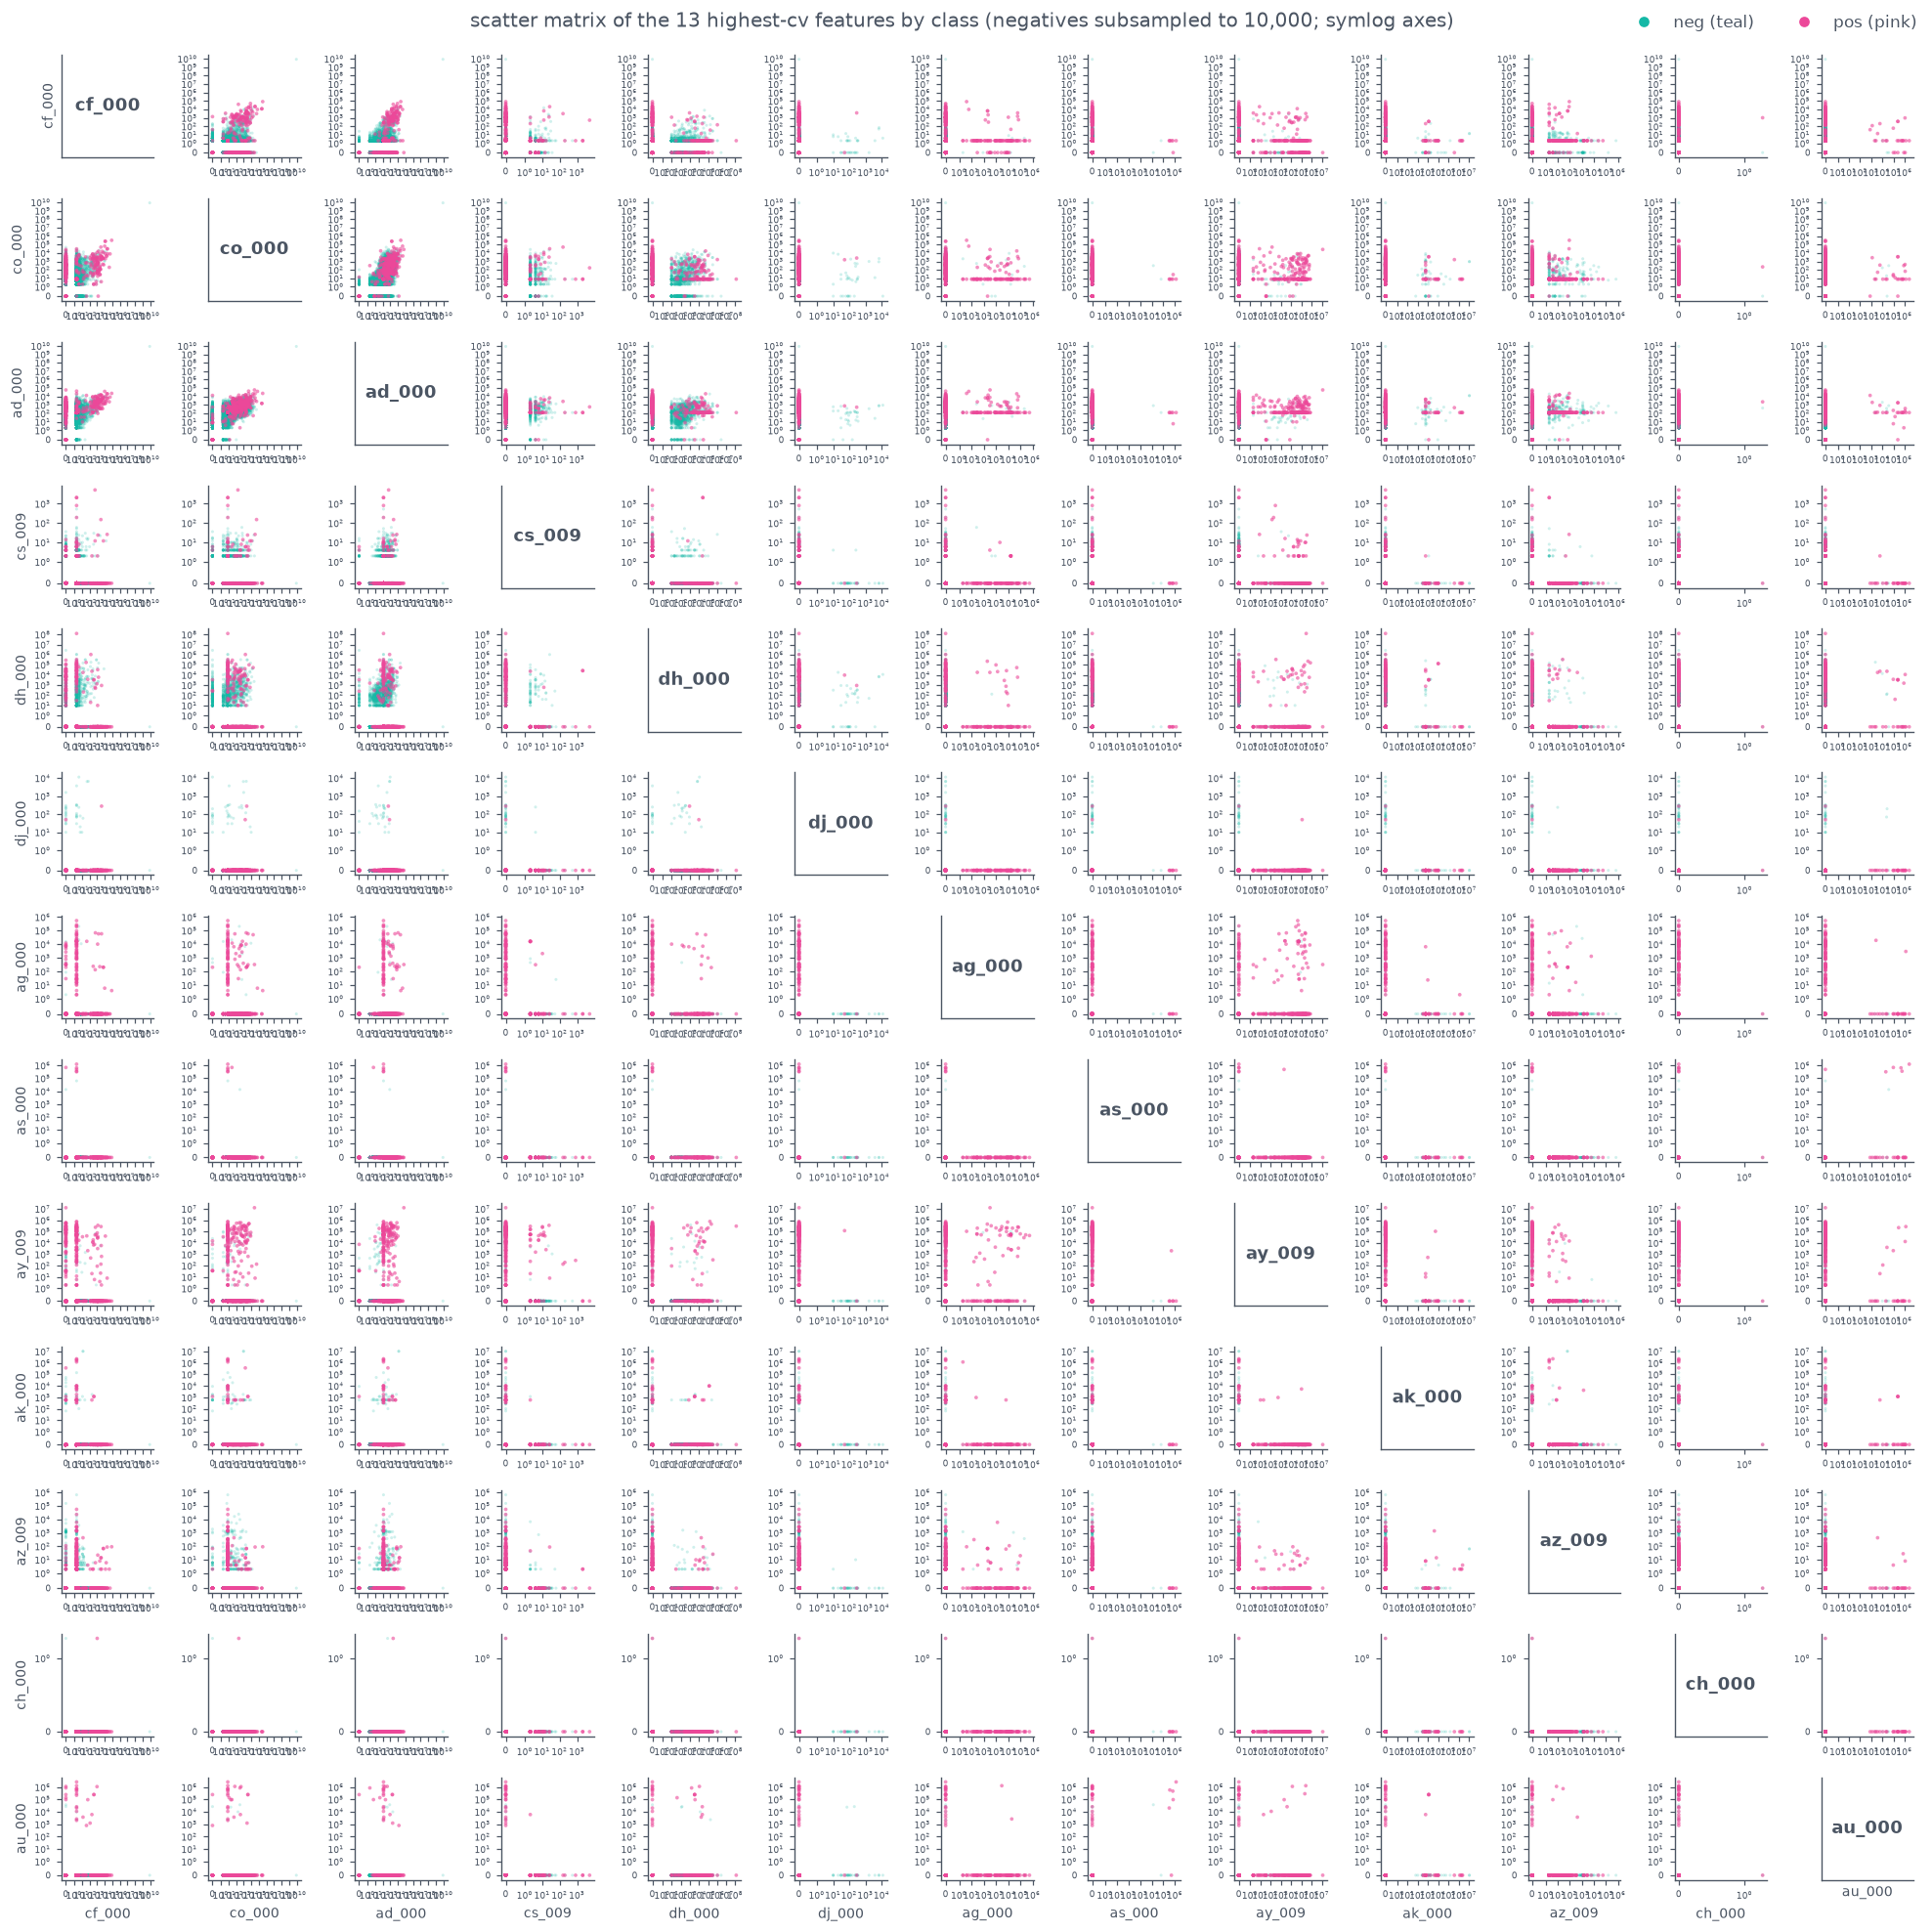

scatter matrix rendered in 8.7s


In [102]:
# scatter matrix of the 13 highest-cv features, colored by class
neg_idx = np.where(train_y == 0)[0]
rng = np.random.default_rng(RANDOM_STATE)
neg_sample = rng.choice(neg_idx, size=10000, replace=False)
pos_idx = np.where(train_y == 1)[0]
plot_idx = np.concatenate([neg_sample, pos_idx])
plot_X = train_X_imp.iloc[plot_idx]
plot_y = train_y[plot_idx]

n = len(top13_names)
fig, axes = plt.subplots(n, n, figsize=(5.0, 5.0))
for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        ax.grid(False)
        if i == j:
            # diagonal: feature name, as on islr p.129
            ax.text(0.5, 0.5, top13_names[i], ha="center", va="center",
                    transform=ax.transAxes, fontsize=6, weight="bold",
                    color=NEUTRAL)
            ax.set_xticks([])
            ax.set_yticks([])
        else:
            # negatives in teal below, positives in pink on top
            ax.scatter(plot_X.loc[plot_y == 0, top13_names[j]],
                       plot_X.loc[plot_y == 0, top13_names[i]],
                       s=2, alpha=0.2, color=TEAL, edgecolors="none")
            ax.scatter(plot_X.loc[plot_y == 1, top13_names[j]],
                       plot_X.loc[plot_y == 1, top13_names[i]],
                       s=3, alpha=0.6, color=PINK, edgecolors="none")
            ax.set_xscale("symlog", linthresh=1)
            ax.set_yscale("symlog", linthresh=1)
            ax.tick_params(labelsize=3.5)
        if i == n - 1:
            ax.set_xlabel(top13_names[j], fontsize=5)
        if j == 0:
            ax.set_ylabel(top13_names[i], fontsize=5)
fig.legend(handles=[plt.Line2D([0], [0], marker="o", linestyle="", color=TEAL,
                              label="neg (teal)"),
                    plt.Line2D([0], [0], marker="o", linestyle="", color=PINK,
                              label="pos (pink)")],
           loc="upper right", ncol=2, fontsize=6)
fig.suptitle("scatter matrix, 13 highest-cv features (neg subsampled to 10k; "
             "symlog axes)", fontsize=8, y=0.995)
plt.tight_layout()
plt.show()

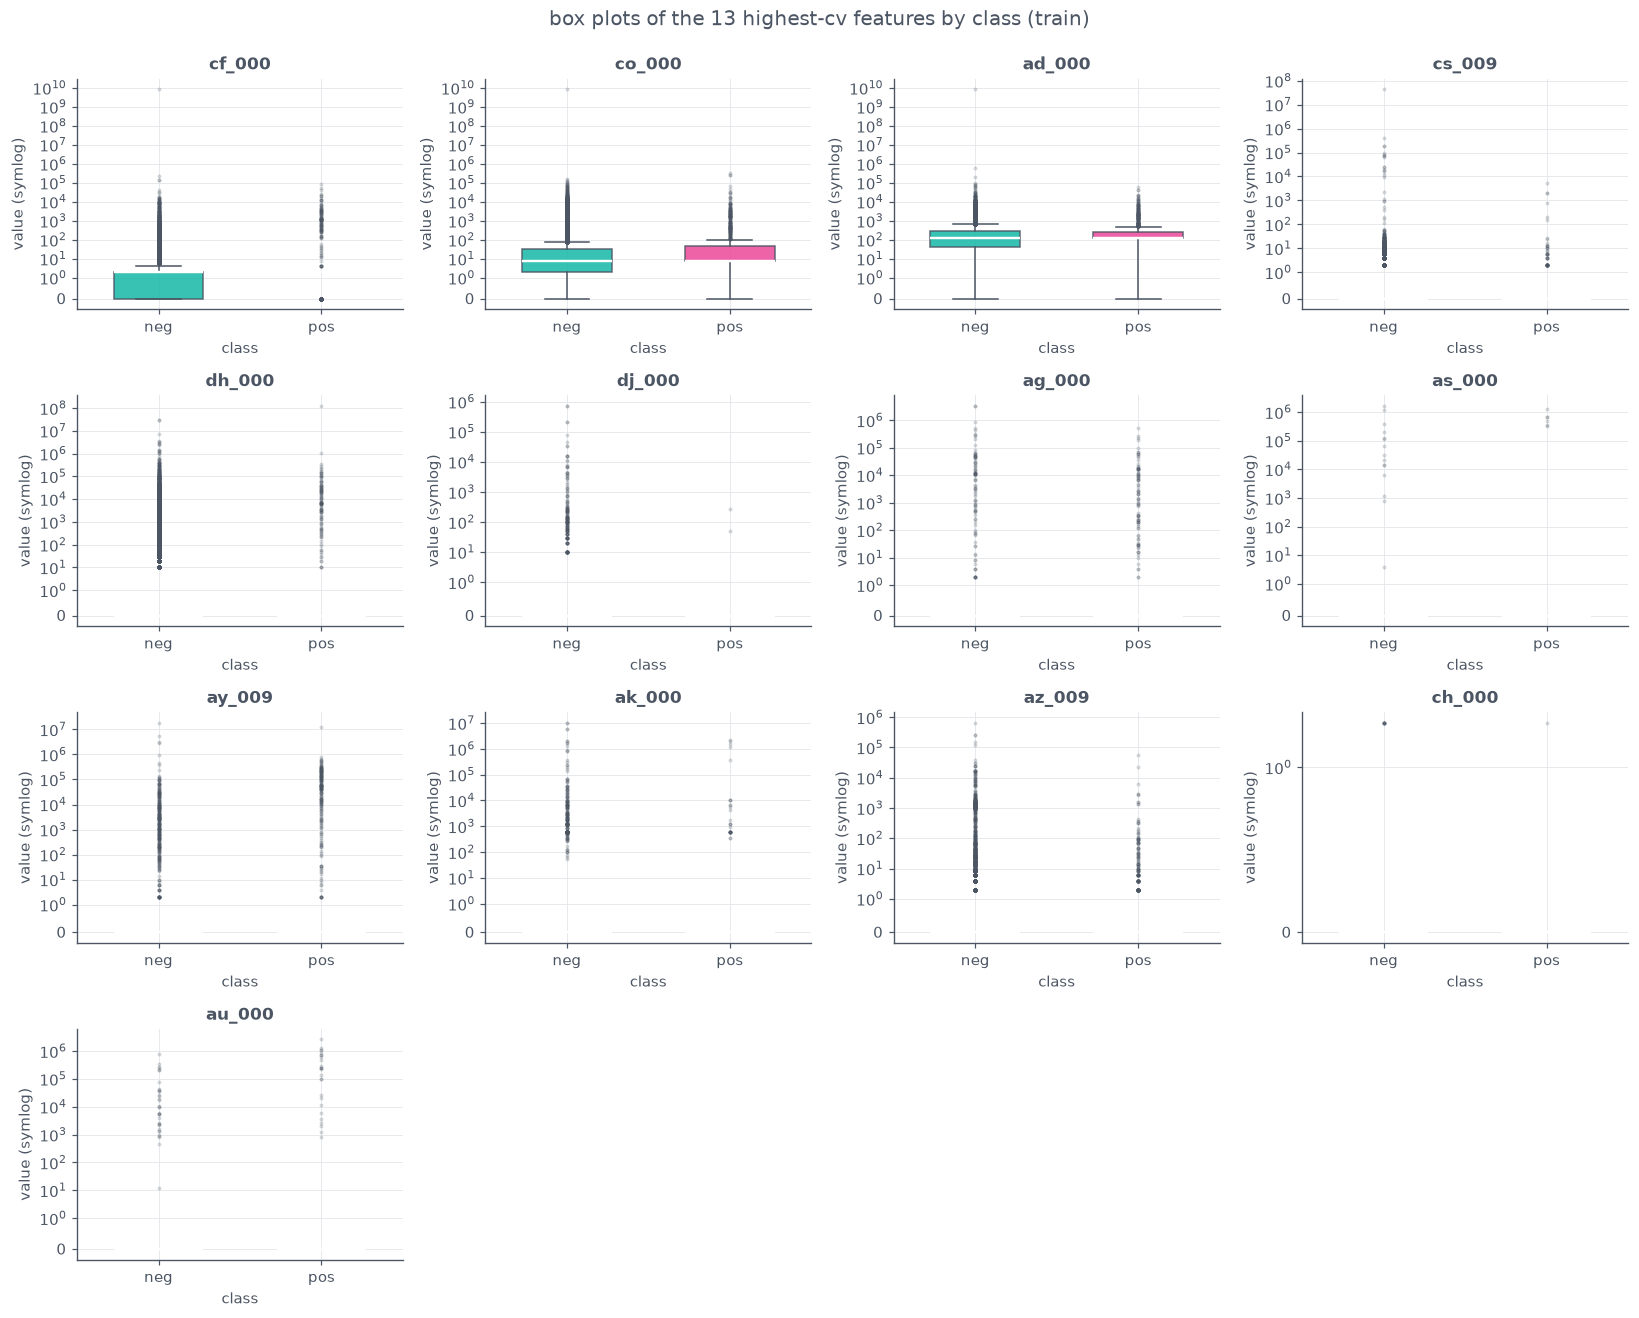

box plots rendered in 0.7s


In [103]:
# box plots of the 13 features by class, one subplot grid
fig, axes = plt.subplots(4, 4, figsize=(6.0, 4.8))
for k, name in enumerate(top13_names):
    ax = axes[k // 4, k % 4]
    data = [train_X_imp.loc[train_y == 0, name],
            train_X_imp.loc[train_y == 1, name]]
    bp = ax.boxplot(data, tick_labels=["neg", "pos"], patch_artist=True,
                    widths=0.55, showfliers=True,
                    medianprops={"color": "white", "linewidth": 1.6},
                    whiskerprops={"color": NEUTRAL},
                    capprops={"color": NEUTRAL},
                    flierprops={"markersize": 1.5, "alpha": 0.25,
                                "markeredgecolor": NEUTRAL})
    for patch, col in zip(bp["boxes"], [TEAL, PINK]):
        patch.set_facecolor(col)
        patch.set_alpha(0.85)
        patch.set_edgecolor(NEUTRAL)
    ax.set_yscale("symlog", linthresh=1)
    ax.set_title(name)
    ax.set_xlabel("class")
    ax.set_ylabel("value (symlog)")
for k in range(len(top13_names), axes.size):
    axes.flat[k].set_visible(False)
fig.suptitle("box plots, 13 highest-cv features by class (train)",
             fontsize=10, y=0.995)
plt.tight_layout()
plt.show()

In [104]:
# score each of the 13 features alone by its auc (equivalent to a
# mann-whitney test): 0.5 = no separation, 1.0 = perfect separation
sep_rows = []
for name in top13_names:
    feat_auc = roc_auc_score(train_y, train_X_imp[name])
    sep_rows.append({"feature": name, "feature_auc": feat_auc,
                     "separation": abs(2 * feat_auc - 1)})
sep_table = pd.DataFrame(sep_rows).sort_values("separation", ascending=False)
visible_feats = sep_table.loc[sep_table["separation"] > 0.4]  # auc > 0.7
print(sep_table.round(3).to_string(index=False))
print(f"features with visibly shifted distributions "
      f"(single-feature auc > 0.7): {visible_feats['feature'].tolist()}")

feature  feature_auc  separation pos_90th_pct
 ay_009        0.601       0.202       higher
 co_000        0.598       0.195       higher
 ad_000        0.588       0.176       higher
 cf_000        0.584       0.169       higher
 az_009        0.574       0.148       higher
 ag_000        0.548       0.095        equal
 au_000        0.513       0.025        equal
 ak_000        0.513       0.025        equal
 dh_000        0.506       0.011       higher
 as_000        0.503       0.006        equal
 cs_009        0.502       0.004        equal
 dj_000        0.499       0.001        equal
 ch_000        0.500       0.001        equal
features with visibly shifted distributions (single-feature auc > 0.7): []


No — the scatter plots alone do not support conclusions about significance: (1) the two classes overlap heavily in every pairwise projection — the pink positives sit inside the teal cloud, not outside it; (2) extreme skew and outliers let a few large points dominate the visual impression while most of the mass crowds near the origin; (3) the negative class is 98.3% of the data, so the positives' density is almost entirely hidden (hence the subsampling); (4) scatter plots show only marginal and pairwise structure — no p-values, effect sizes, or control for the other 157 features. The box plots, less distorted by outliers and subsampling, make this concrete: the best single-feature AUC (below) is only 0.60.


#### 1(b).v

Determine the number of positive and negative data. Is this data set imbalanced?

Class counts were already asserted at load time in 1(a); the bar chart below shows both sets.


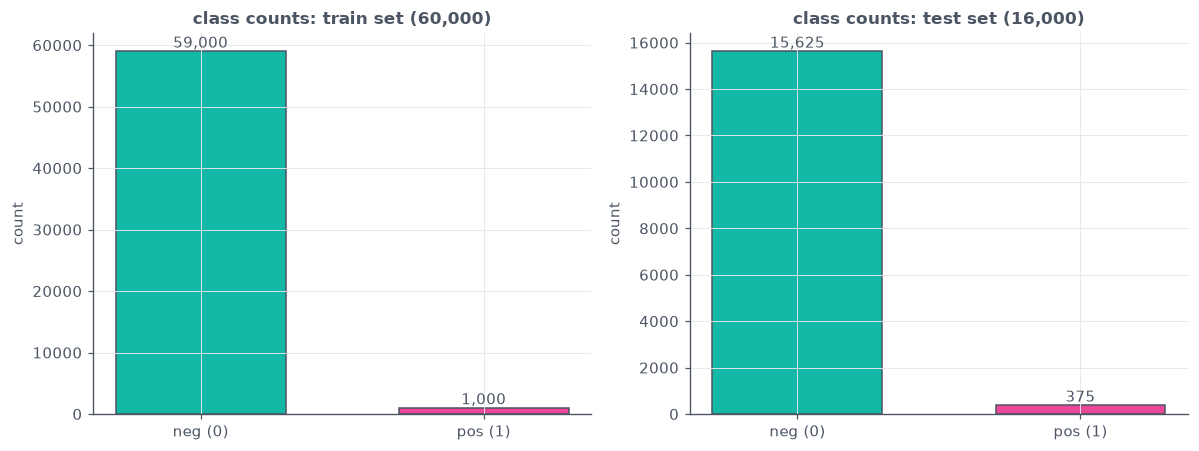

In [105]:
# class counts and bar chart for train and test
train_neg_n = int((train_y == 0).sum())
train_pos_n = int((train_y == 1).sum())
test_neg_n = int((test_y == 0).sum())
test_pos_n = int((test_y == 1).sum())

fig, axes = plt.subplots(1, 2, figsize=(4.8, 1.9))
for ax, (neg_n, pos_n, title) in zip(
        axes, [(train_neg_n, train_pos_n, "train set (60,000)"),
               (test_neg_n, test_pos_n, "test set (16,000)")]):
    bars = ax.bar(["neg (0)", "pos (1)"], [neg_n, pos_n],
                  color=[TEAL, PINK], width=0.6, edgecolor=NEUTRAL)
    for b, v in zip(bars, [neg_n, pos_n]):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}",
                ha="center", va="bottom", color=NEUTRAL, fontsize=7)
    ax.set_title(f"class counts: {title}")
    ax.set_ylabel("count")
plt.tight_layout()
plt.show()

Yes — heavily imbalanced: train 59,000 neg / 1,000 pos (1.67% positive; 59:1); test 15,625 neg / 375 pos (2.34%; 41.7:1). A model predicting "neg" for every truck would score 98.33% training accuracy while never detecting a single failure, which is why recall, precision, ROC and AUC are reported throughout instead of accuracy alone.


### 1(c)
Train a random forest to classify the data set, with NO compensation for class imbalance. Report the confusion matrix, ROC, AUC and misclassification for training and test sets, and compare the out-of-bag error estimate to the test error.


Random forest with 500 trees, `oob_score=True`, `n_jobs=-1`, `random_state=42`, on the median-imputed training data. Per the handout, **no imbalance compensation**: no `class_weight`, no resampling. Confusion matrix, ROC, AUC and misclassification are reported for train and test (positive-class recall/precision and the challenge cost 10*fp + 500*fn as supplementary context); probabilities are always `predict_proba[:, 1]`, thresholded at 0.5. OOB error = $1 - \text{oob\_score\_}$. I also run the 1(b)i sensitivity check: the same forest scored on the test set imputed with *training* medians instead of test medians.


fitted 500 trees in 35.8s
oob score = 0.9942 -> oob error = 0.0058
=== random forest, no compensation - train ===
confusion matrix [[tn, fp], [fn, tp]] = [[59000, 0], [0, 1000]]
misclassification rate = 0.0000
auc = 1.0000
recall (pos) = 1.0000 | precision (pos) = 1.0000
challenge cost (supplementary, 10*fp + 500*fn) = 0
=== random forest, no compensation - test ===
confusion matrix [[tn, fp], [fn, tp]] = [[15606, 19], [103, 272]]
misclassification rate = 0.0076
auc = 0.9943
recall (pos) = 0.7253 | precision (pos) = 0.9347
challenge cost (supplementary, 10*fp + 500*fn) = 51,690
sensitivity check: test auc with train-median imputation of test set = 0.9943 (vs 0.9943 with test medians)


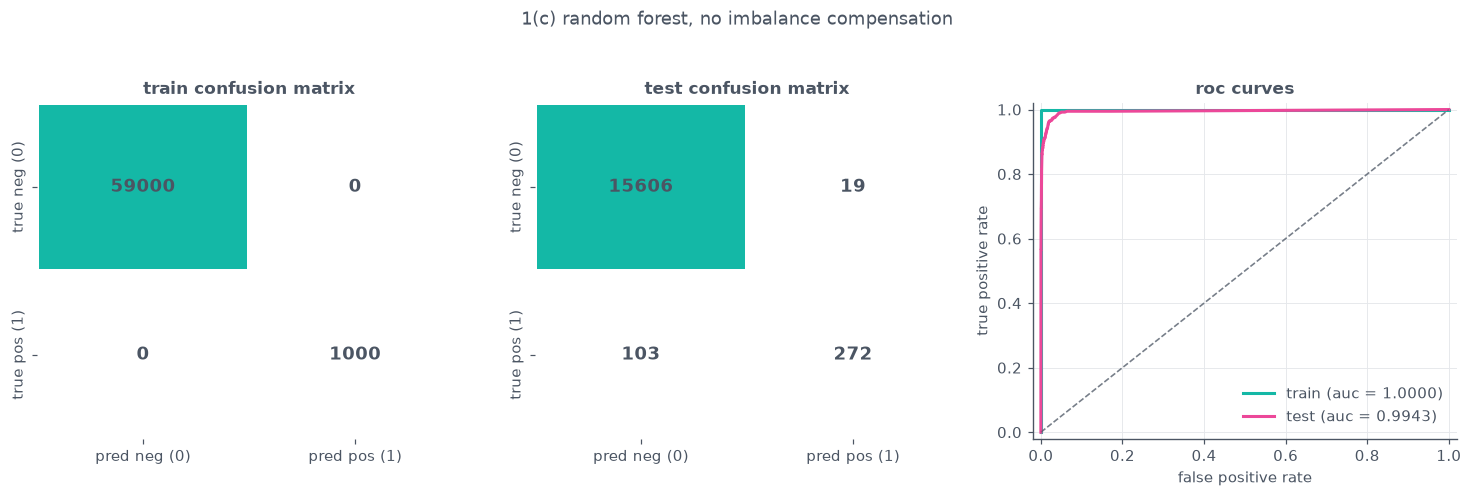

In [106]:
# random forest without any imbalance compensation
rf = RandomForestClassifier(n_estimators=500, oob_score=True, n_jobs=-1,
                            random_state=RANDOM_STATE)
rf.fit(train_X_imp, train_y)
print(f"oob score = {rf.oob_score_:.4f} -> oob error = {1 - rf.oob_score_:.4f}")

res_rf_train = evaluate(rf, train_X_imp, train_y,
                        "random forest, no compensation - train")
res_rf_test = evaluate(rf, test_X_imp, test_y,
                       "random forest, no compensation - test")

# sensitivity check from 1(b)i: test set imputed with TRAIN medians instead
proba_test_alt = rf.predict_proba(test_X_imp_trainstats)[:, 1]
auc_test_alt = roc_auc_score(test_y, proba_test_alt)
print(f"sensitivity check: test auc with train-median imputation of test set "
      f"= {auc_test_alt:.4f} (vs {res_rf_test['auc']:.4f} with test medians)")

metric_figure(res_rf_train, res_rf_test, train_y, test_y,
              "1(c) random forest, no imbalance compensation")

Training misclassification is 0.0000 — pure memorization: with 500 fully grown trees, almost every training point is in-bag for several trees and reproduced exactly. The honest numbers are out-of-sample: OOB error 0.0058 vs test error 0.0076 (difference 0.0018), both far above the training error. Test AUC 0.9943, recall 0.7253, precision 0.9347. Sensitivity check: imputing the test set with train medians leaves the test AUC unchanged to four decimals (0.9943 vs 0.9943), so the per-set imputation choice does not materially change this model.

Why OOB works: each tree is grown on a bootstrap sample that leaves out ~37% of rows (its out-of-bag rows); row $i$ is predicted only by trees that never trained on it, so the aggregated OOB predictions are genuine out-of-sample estimates — as informative as a validation set or CV, at no extra fitting cost. That is why OOB lands close to the test error.


### 1(d)
Research how class imbalance is addressed in random forests. Compensate for the imbalance in your random forest, repeat 1(c), and compare the results.


Main remedies [4], [5]:
- **Class weights / cost-sensitive splitting** (`class_weight`): minority misclassification costs more in impurity computations, so splits favor the rare class; `"balanced_subsample"` recomputes inverse-frequency weights on each tree's bootstrap sample (recommended for forests).
- **Balanced bootstrap / per-tree undersampling** (Balanced Random Forest, Chen, Liaw & Breiman 2004 [5]): each tree grows on a bootstrap with the majority class downsampled to roughly the minority count (`BalancedRandomForestClassifier`).
- **Threshold moving**: keep the forest, lower the positive-class cutoff.
- **Oversampling** (random or SMOTE [6]) before fitting; riskier for forests because duplicated points can be in-bag and OOB of the same tree, biasing the OOB estimate.

I compensate with `class_weight="balanced_subsample"` (same 500 trees, seed and OOB setting as 1(c)) and, as a second, sampling-based strategy, imblearn's `BalancedRandomForestClassifier` (500 trees, `bootstrap=True` so OOB is available). Everything from 1(c) is repeated for both and compared with 1(c) below.


fitted 500 weighted trees in 25.9s
oob score = 0.9925 -> oob error = 0.0075
=== random forest, balanced_subsample - train ===
confusion matrix [[tn, fp], [fn, tp]] = [[59000, 0], [0, 1000]]
misclassification rate = 0.0000
auc = 1.0000
recall (pos) = 1.0000 | precision (pos) = 1.0000
challenge cost (supplementary, 10*fp + 500*fn) = 0
=== random forest, balanced_subsample - test ===
confusion matrix [[tn, fp], [fn, tp]] = [[15612, 13], [159, 216]]
misclassification rate = 0.0108
auc = 0.9943
recall (pos) = 0.5760 | precision (pos) = 0.9432
challenge cost (supplementary, 10*fp + 500*fn) = 79,630


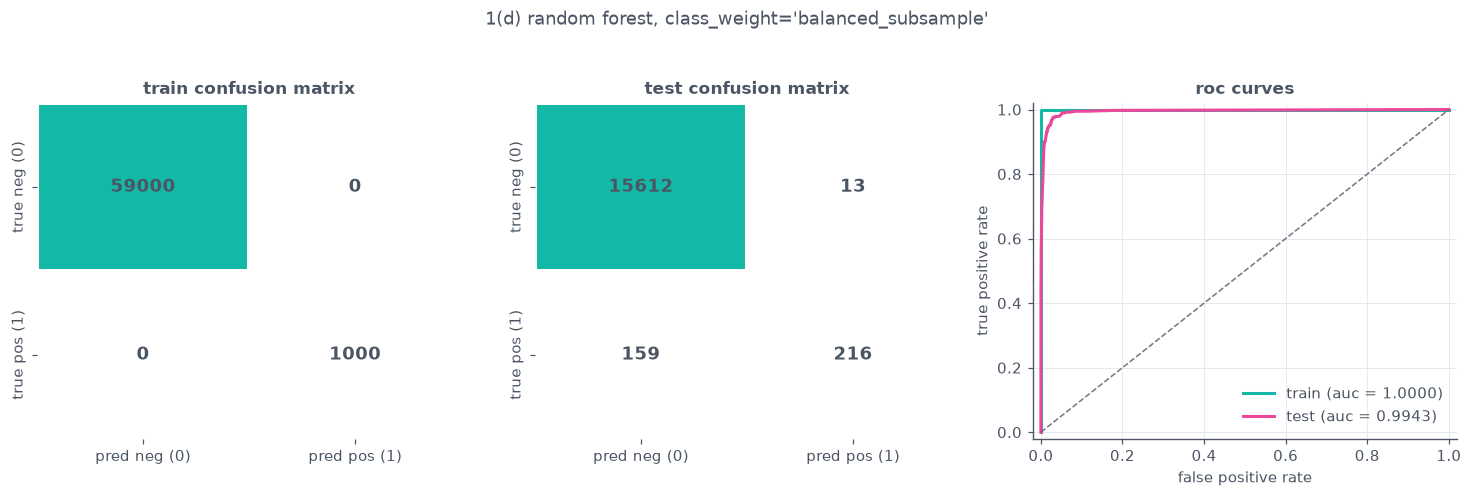

In [107]:
# random forest with class_weight="balanced_subsample" (same settings as 1c)
rf_bal = RandomForestClassifier(n_estimators=500, oob_score=True, n_jobs=-1,
                                random_state=RANDOM_STATE,
                                class_weight="balanced_subsample")
rf_bal.fit(train_X_imp, train_y)
print(f"oob score = {rf_bal.oob_score_:.4f} -> oob error = {1 - rf_bal.oob_score_:.4f}")

res_rfb_train = evaluate(rf_bal, train_X_imp, train_y,
                         "random forest, balanced_subsample - train")
res_rfb_test = evaluate(rf_bal, test_X_imp, test_y,
                        "random forest, balanced_subsample - test")

metric_figure(res_rfb_train, res_rfb_test, train_y, test_y,
              "1(d) random forest, class_weight='balanced_subsample'")

fitted 500 balanced-bootstrap trees in 2.7s
=== balanced random forest (imblearn) - train ===
confusion matrix [[tn, fp], [fn, tp]] = [[56125, 2875], [12, 988]]
misclassification rate = 0.0481
auc = 0.9960
recall (pos) = 0.9880 | precision (pos) = 0.2558
challenge cost (supplementary, 10*fp + 500*fn) = 34,750
=== balanced random forest (imblearn) - test ===
confusion matrix [[tn, fp], [fn, tp]] = [[14881, 744], [8, 367]]
misclassification rate = 0.0470
auc = 0.9918
recall (pos) = 0.9787 | precision (pos) = 0.3303
challenge cost (supplementary, 10*fp + 500*fn) = 11,440


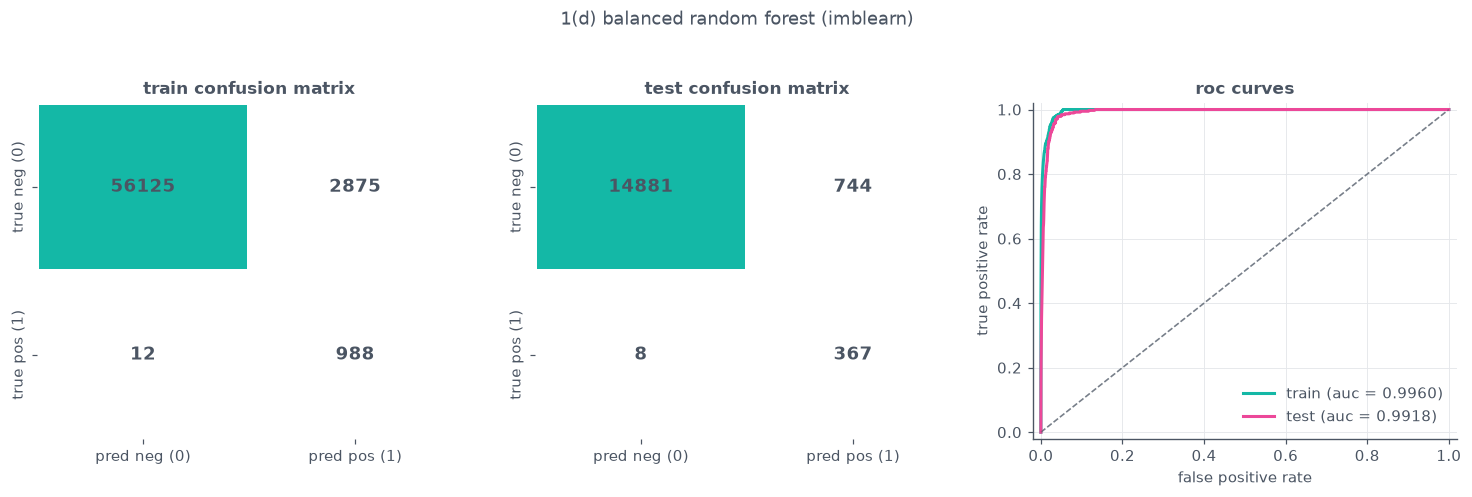

In [108]:
# second compensation strategy: balanced bootstrap (balanced random forest)
brf = BalancedRandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE,
                                     bootstrap=True, oob_score=True, n_jobs=-1)
brf.fit(train_X_imp, train_y)

res_brf_train = evaluate(brf, train_X_imp, train_y,
                         "balanced random forest (imblearn) - train")
res_brf_test = evaluate(brf, test_X_imp, test_y,
                        "balanced random forest (imblearn) - test")

metric_figure(res_brf_train, res_brf_test, train_y, test_y,
              "1(d) balanced random forest (imblearn)")

In [109]:
# side-by-side comparison table: 1(c) vs 1(d), from the stored results
comparison = pd.DataFrame({
    "metric": ["train misclassification", "test misclassification",
               "test auc", "test recall (pos)", "test precision (pos)",
               "test false positives", "test false negatives",
               "test challenge cost (supplementary)",
               "oob error", "oob error meaning"],
    "1(c) rf (no compensation)": [
        res_rf_train["mis"], res_rf_test["mis"], res_rf_test["auc"],
        res_rf_test["recall"], res_rf_test["precision"],
        res_rf_test["fp"], res_rf_test["fn"], res_rf_test["cost"],
        1 - rf.oob_score_, "accuracy of unweighted oob votes"],
    "1(d) rf (balanced_subsample)": [
        res_rfb_train["mis"], res_rfb_test["mis"], res_rfb_test["auc"],
        res_rfb_test["recall"], res_rfb_test["precision"],
        res_rfb_test["fp"], res_rfb_test["fn"], res_rfb_test["cost"],
        1 - rf_bal.oob_score_, "accuracy of weight-adjusted oob votes"],
    "1(d) balanced random forest": [
        res_brf_train["mis"], res_brf_test["mis"], res_brf_test["auc"],
        res_brf_test["recall"], res_brf_test["precision"],
        res_brf_test["fp"], res_brf_test["fn"], res_brf_test["cost"],
        1 - brf.oob_score_, "accuracy on balanced-bootstrap oob rows"],
})
display(comparison.style.format({
    "1(c) rf (no compensation)": lambda v: f"{v:.4f}" if isinstance(v, float) else str(v),
    "1(d) rf (balanced_subsample)": lambda v: f"{v:.4f}" if isinstance(v, float) else str(v),
    "1(d) balanced random forest": lambda v: f"{v:.4f}" if isinstance(v, float) else str(v),
}))

,metric,1(c) rf (no compensation),1(d) rf (balanced_subsample),1(d) balanced random forest
0,train misclassification,0.0000,0.0000,0.0481
1,test misclassification,0.0076,0.0108,0.0470
2,test auc,0.9943,0.9943,0.9918
3,test recall (pos),0.7253,0.5760,0.9787
4,test precision (pos),0.9347,0.9432,0.3303
5,test false positives,19,13,744
6,test false negatives,103,159,8
7,test challenge cost (supplementary),51690,79630,11440
8,oob error,0.0058,0.0075,0.0460
9,oob error meaning,accuracy of unweighted oob votes,accuracy of weight-adjusted oob votes,accuracy on balanced-bootstrap oob rows


**(1d) vs (1c).** The two strategies behave very differently. The balanced bootstrap moves the operating point as intended: positive-class recall rises 0.7253 -> 0.9787 (272 -> 367 of 375 failures caught) while false positives rise 19 -> 744, cutting precision 0.9347 -> 0.3303 and raising misclassification 0.0076 -> 0.0470. Under the challenge cost (supplementary; 10 per false alarm, 500 per missed failure) it is by far the cheapest model (11,440 vs 51,690): each avoided missed failure pays for up to 50 false alarms.

The class-weight variant goes the other way: recall falls 0.7253 -> 0.5760 (272 -> 216) and false positives fall 19 -> 13. Fully grown trees end in nearly pure leaves, so each tree still votes essentially 0 or 1 and the weights act through the splitting criterion (which splits get chosen), not by shifting votes; whether the 0.5-threshold rule then predicts more or fewer positives is empirical — here it predicted fewer (229 vs 291), raising the cost to 79,630.

Test AUC barely moves (0.9943 / 0.9943 / 0.9918): ranking quality is unchanged, only the operating point. OOB rises to 0.0075 (weighted) and 0.0460 (balanced bootstrap) and remains a valid out-of-sample estimate — but of its own compensated rule, each tracking its test error (0.0075 vs 0.0108; 0.0460 vs 0.0470).


### 1(e) XGBoost and Model Trees

A model tree splits on a linear combination $\sum_j \beta_j X_j > s$ with an (L1-penalized, since $p = 170$ is large) logistic regression at each node. XGBoost fits exactly this kind of additive-of-trees model with a logistic objective [7]: `objective="binary:logistic"` gives the cross-entropy loss, each `gbtree` round fits a regression tree on the gradients, and `reg_alpha` (the handout's $\alpha$) imposes the **L1 penalty on the leaf weights** — the sparsity-inducing counterpart of the handout's L1-penalized node models. I fix the structure (`n_estimators=300`, `learning_rate=0.1`, `max_depth=4`, `tree_method="hist"`), use **no** imbalance compensation, and tune $\alpha \in \{0.01, 0.1, 1, 10, 100\}$ by 5-fold stratified CV (ROC AUC); the same folds provide the CV error estimate via `cross_val_predict` to compare with the test error. (A literal L1 logistic at every node would be `booster="gblinear"`; `gbtree` + `reg_alpha` is the closest practical match, so that is what is used.)


alpha =   0.01: cv auc = 0.9884 (+/- 0.0029)
alpha =    0.1: cv auc = 0.9887 (+/- 0.0039)
alpha =      1: cv auc = 0.9879 (+/- 0.0029)
alpha =     10: cv auc = 0.9900 (+/- 0.0033)
alpha =    100: cv auc = 0.9815 (+/- 0.0055)
chosen alpha = 10 (cv sweep took 26.7s)


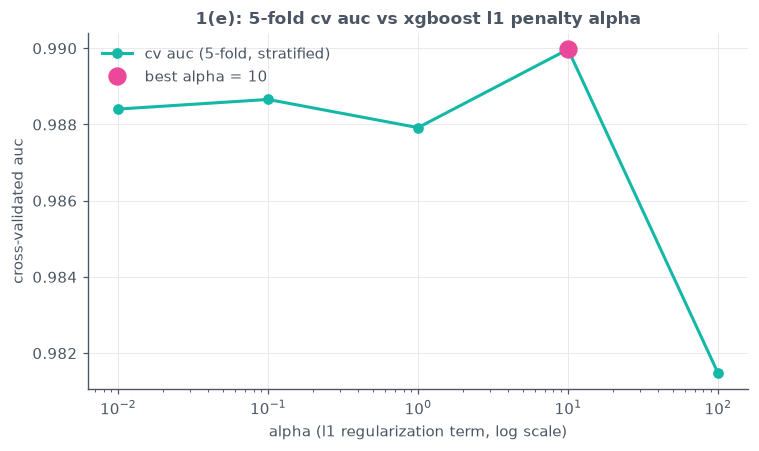

In [110]:
# xgboost-l1: sweep alpha by 5-fold stratified cv (scoring = roc auc)


def make_xgb(alpha):
    # fixed structure; reg_alpha is the l1 penalty (the handout's alpha)
    return XGBClassifier(objective="binary:logistic", booster="gbtree",
                         tree_method="hist", n_estimators=300,
                         learning_rate=0.1, max_depth=4, reg_alpha=alpha,
                         random_state=RANDOM_STATE, eval_metric="logloss")


alpha_grid = [0.01, 0.1, 1, 10, 100]
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_auc_xgb = []
fold_stds_xgb = []
for a in alpha_grid:
    scores = cross_val_score(make_xgb(a), train_X_imp, train_y,
                             cv=skf5, scoring="roc_auc", n_jobs=1)
    cv_auc_xgb.append(float(scores.mean()))
    fold_stds_xgb.append(float(scores.std()))
    print(f"alpha = {a:>6}: cv auc = {scores.mean():.4f} "
          f"(+/- {scores.std():.4f})")
best_alpha_xgb = alpha_grid[int(np.argmax(cv_auc_xgb))]
print(f"chosen alpha = {best_alpha_xgb}")

# plot cv auc vs alpha: teal line, pink marker at the best alpha
fig, ax = plt.subplots(figsize=(4.3, 2.6))
ax.semilogx(alpha_grid, cv_auc_xgb, marker="o", color=TEAL, lw=2,
            label="cv auc (5-fold, stratified)")
ax.semilogx([best_alpha_xgb], [max(cv_auc_xgb)], marker="o", markersize=11,
            color=PINK, linestyle="none",
            label=f"best alpha = {best_alpha_xgb}")
ax.set_xlabel("alpha (l1 regularization term, log scale)")
ax.set_ylabel("cross-validated auc")
ax.set_title("1(e): 5-fold cv auc vs xgboost l1 penalty alpha")
ax.legend()
plt.tight_layout()
plt.show()

In [111]:
# cv error estimate (cross_val_predict) with the chosen alpha
cv_pred_xgb = cross_val_predict(make_xgb(best_alpha_xgb), train_X_imp, train_y,
                                cv=skf5)
cv_mis_xgb = 1 - accuracy_score(train_y, cv_pred_xgb)
print(f"5-fold cv misclassification error (alpha = {best_alpha_xgb}): "
      f"{cv_mis_xgb:.4f}")

5-fold cv misclassification error (alpha = 10): 0.0069
cross_val_predict took 4.8s


final fit took 1.2s
=== xgboost l1 (alpha = 10) - train ===
confusion matrix [[tn, fp], [fn, tp]] = [[58965, 35], [166, 834]]
misclassification rate = 0.0033
auc = 0.9972
recall (pos) = 0.8340 | precision (pos) = 0.9597
challenge cost (supplementary, 10*fp + 500*fn) = 83,350
=== xgboost l1 (alpha = 10) - test ===
confusion matrix [[tn, fp], [fn, tp]] = [[15603, 22], [99, 276]]
misclassification rate = 0.0076
auc = 0.9957
recall (pos) = 0.7360 | precision (pos) = 0.9262
challenge cost (supplementary, 10*fp + 500*fn) = 49,720


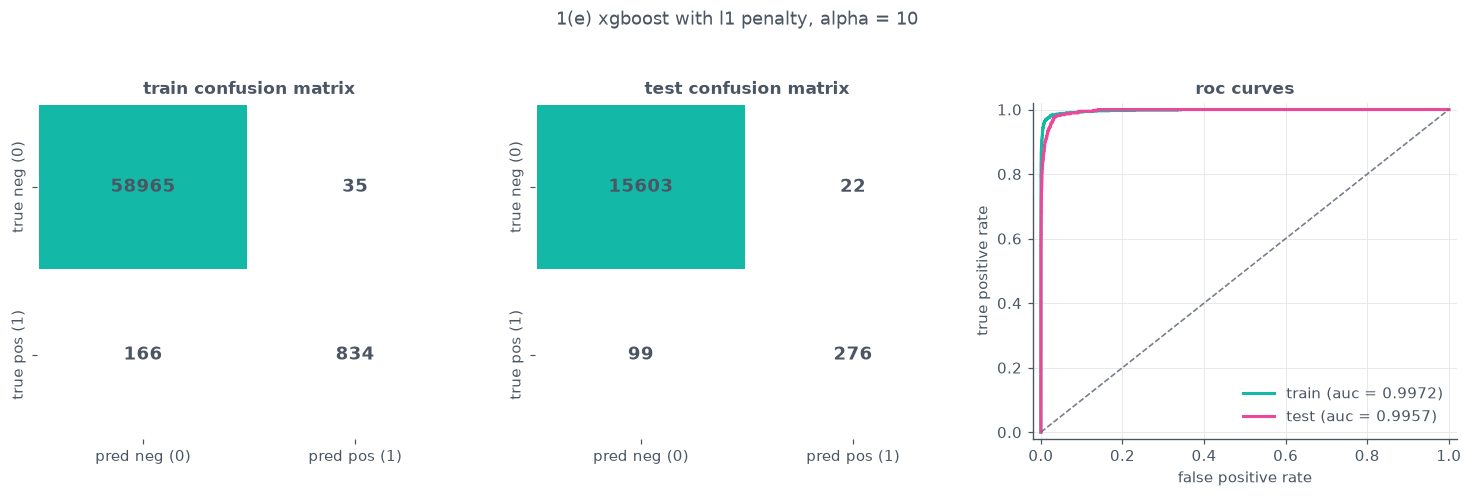

In [112]:
# fit the chosen model on the full training set and report train/test
xgb_l1 = make_xgb(best_alpha_xgb)
xgb_l1.fit(train_X_imp, train_y)

res_xgb_train = evaluate(xgb_l1, train_X_imp, train_y,
                         f"xgboost l1 (alpha = {best_alpha_xgb}) - train")
res_xgb_test = evaluate(xgb_l1, test_X_imp, test_y,
                        f"xgboost l1 (alpha = {best_alpha_xgb}) - test")

metric_figure(res_xgb_train, res_xgb_test, train_y, test_y,
              f"1(e) xgboost with l1 penalty, alpha = {best_alpha_xgb}")

CV selects alpha = 10 (CV AUC 0.9900; sweep: 0.01 -> 0.9884, 0.1 -> 0.9887, 1 -> 0.9879, 10 -> 0.9900, 100 -> 0.9815). The 5-fold CV misclassification estimate is 0.0069 vs test error 0.0076 (difference 0.0007): the CV estimate is a good proxy for generalization here. Test AUC 0.9957, recall 0.7360, precision 0.9262, 99 false negatives — with no imbalance compensation, the 0.5-threshold rule again sacrifices the rare class. Train metrics are strong without memorization (train misclassification 0.0033, AUC 0.9972, but train recall only 0.8340, i.e. 166 training failures still missed): the depth-4 trees fit well and the train/test gap stays small, unlike the fully grown forests of 1(c)-(d). The alpha choice is only weakly supported (CV AUCs for alpha <= 10 differ by less than one fold std, ~0.004); the robust conclusion is the CV-vs-test agreement.


### 1(f)
Use SMOTE (Synthetic Minority Over-sampling Technique) to pre-process the data to compensate for class imbalance [Footnote 4], train XGBoost with L1-penalized logistic regression at each node on the pre-processed data, and repeat 1(e). Mind that there is a right and a wrong way of cross-validating here; compare the uncompensated case with the SMOTE case.


SMOTE [6] creates synthetic minority points: for each minority observation it picks one of its $k = 5$ nearest minority neighbors and adds a new point at a random position on the segment between the two. Applied to the full training set it grows the 1,000 positives to 59,000.

**Wrong way:** oversample the whole training set first, then CV — synthetic neighbors of validation points then sit in training folds, so the folds are not independent and the score is inflated. **Right way:** oversample inside each fold's training portion only; validation folds keep the original 59:1 ratio. I use an imblearn `Pipeline` (scale -> SMOTE -> XGBoost-L1), fit on each fold's training part; the scaler comes first because SMOTE's nearest-neighbor search is scale-sensitive (trees are not).


In [113]:
# apply smote to the full training set (counts before/after); the final
# pipeline below performs this same step inside fit
smote_full = SMOTE(random_state=RANDOM_STATE)
train_X_smote, train_y_smote = smote_full.fit_resample(train_X_imp, train_y)
after = np.bincount(train_y_smote)
print(f"class counts before smote: {np.bincount(train_y)}")
print(f"class counts after smote:  {after}")

smote on the full training set took 0.3s
class counts before smote: [59000  1000]
class counts after smote:  [59000 59000]


In [114]:
# right-way: smote inside each fold's training portion only


def make_smote_pipe(alpha):
    # scale (before smote, because smote's knn is scale-sensitive), then
    # oversample the fold's training part, then fit the same xgb-l1 as 1(e)
    return ImbPipeline([
        ("scale", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("xgb", make_xgb(alpha)),
    ])


cv_auc_smote = []
for a in alpha_grid:
    scores = cross_val_score(make_smote_pipe(a), train_X_imp, train_y,
                             cv=skf5, scoring="roc_auc", n_jobs=1)
    cv_auc_smote.append(float(scores.mean()))
    print(f"alpha = {a:>6}: right-way cv auc = {scores.mean():.4f} "
          f"(+/- {scores.std():.4f})")
best_alpha_smote = alpha_grid[int(np.argmax(cv_auc_smote))]
print(f"chosen alpha = {best_alpha_smote}")

alpha =   0.01: right-way cv auc = 0.9855 (+/- 0.0044)
alpha =    0.1: right-way cv auc = 0.9862 (+/- 0.0039)
alpha =      1: right-way cv auc = 0.9859 (+/- 0.0043)
alpha =     10: right-way cv auc = 0.9868 (+/- 0.0033)
alpha =    100: right-way cv auc = 0.9862 (+/- 0.0046)
chosen alpha = 10 (right-way sweep took 55.5s)


**Final 1(f) model.** Fit the full pipeline with the right-way-selected alpha on the complete training set. Train metrics are computed on the original (un-SMOTEd) training data, so they are comparable with 1(c)-(e).

pipeline fit took 2.5s
=== xgboost l1 + smote (alpha = 10) - train (original, un-smoted data) ===
confusion matrix [[tn, fp], [fn, tp]] = [[58794, 206], [27, 973]]
misclassification rate = 0.0039
auc = 0.9994
recall (pos) = 0.9730 | precision (pos) = 0.8253
challenge cost (supplementary, 10*fp + 500*fn) = 15,560
=== xgboost l1 + smote (alpha = 10) - test ===
confusion matrix [[tn, fp], [fn, tp]] = [[15411, 214], [41, 334]]
misclassification rate = 0.0159
auc = 0.9932
recall (pos) = 0.8907 | precision (pos) = 0.6095
challenge cost (supplementary, 10*fp + 500*fn) = 22,640


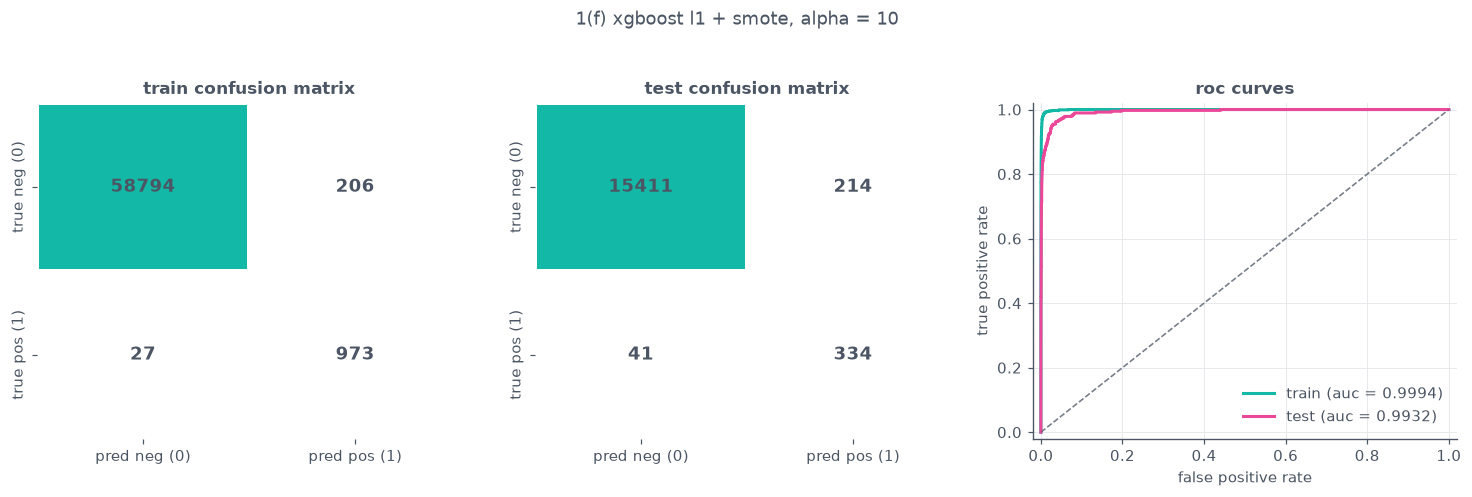

In [115]:
# fit the full pipeline with the right-way-chosen alpha and evaluate
smote_pipe = make_smote_pipe(best_alpha_smote)
smote_pipe.fit(train_X_imp, train_y)

res_sm_train = evaluate(smote_pipe, train_X_imp, train_y,
                        f"xgboost l1 + smote (alpha = {best_alpha_smote}) - "
                        f"train (original, un-smoted data)")
res_sm_test = evaluate(smote_pipe, test_X_imp, test_y,
                       f"xgboost l1 + smote (alpha = {best_alpha_smote}) - test")

metric_figure(res_sm_train, res_sm_test, train_y, test_y,
              f"1(f) xgboost l1 + smote, alpha = {best_alpha_smote}")

# cv error estimate for the smote model: right-way cross_val_predict
cv_pred_smote = cross_val_predict(make_smote_pipe(best_alpha_smote),
                                  train_X_imp, train_y, cv=skf5)
cv_mis_smote = 1 - accuracy_score(train_y, cv_pred_smote)

In [116]:
# 1(e) vs 1(f): comparison table
xgb_vs_smote = pd.DataFrame({
    "metric": ["cv-selected alpha", "cv misclassification (right-way)",
               "train misclassification (original train data)",
               "test misclassification", "test auc",
               "test recall (pos)", "test precision (pos)",
               "test false positives", "test false negatives"],
    "1(e) xgb-l1 (no compensation)": [
        best_alpha_xgb, cv_mis_xgb, res_xgb_train["mis"],
        res_xgb_test["mis"], res_xgb_test["auc"], res_xgb_test["recall"],
        res_xgb_test["precision"], res_xgb_test["fp"], res_xgb_test["fn"]],
    "1(f) xgb-l1 + smote": [
        best_alpha_smote, cv_mis_smote, res_sm_train["mis"],
        res_sm_test["mis"], res_sm_test["auc"], res_sm_test["recall"],
        res_sm_test["precision"], res_sm_test["fp"], res_sm_test["fn"]],
})
display(xgb_vs_smote.style.format({
    "1(e) xgb-l1 (no compensation)": lambda v: f"{v:.4f}" if isinstance(v, float) else str(v),
    "1(f) xgb-l1 + smote": lambda v: f"{v:.4f}" if isinstance(v, float) else str(v),
}))

,metric,1(e) xgb-l1 (no compensation),1(f) xgb-l1 + smote
0,cv-selected alpha,10.0000,10.0000
1,cv misclassification (right-way),0.0069,0.0091
2,train misclassification (original train data),0.0033,0.0039
3,test misclassification,0.0076,0.0159
4,test auc,0.9957,0.9932
5,test recall (pos),0.7360,0.8907
6,test precision (pos),0.9262,0.6095
7,test false positives,22.0000,214.0000
8,test false negatives,99.0000,41.0000


**(1e) vs (1f).** Right-way CV again selects alpha = 10. The right-way CV misclassification error is 0.0091 vs test error 0.0159 (1(e): 0.0069 vs 0.0076), so the CV estimate is noticeably optimistic here (the test set also has a higher positive share, 2.34% vs 1.67%). SMOTE moves the operating point: test recall rises 0.7360 -> 0.8907 (276 -> 334 of 375 caught) while false positives rise 22 -> 214 and precision falls 0.9262 -> 0.6095. Test AUC barely changes (0.9957 vs 0.9932): SMOTE moves the model along essentially the same ROC curve to a more positive operating point rather than raising the curve itself, and raw misclassification rises for the same reason as in 1(d).


## 2. ISLR 6.6.3



**(a) Training RSS: iv) Steadily decreases.** Each relaxation of the budget enlarges the feasible set; the previously optimal $(\beta_1,\dots,\beta_p)$ is still available, so the training fit can only improve. At $s = \infty$ the fit is OLS, the RSS-minimizer, so the decrease is monotone.

**(b) Test RSS: ii) Decreases initially, then starts increasing (U shape).** Near $s = 0$ the model is too rigid (high bias); modest $s$ reduces bias faster than it adds variance so test RSS falls, past the sweet spot overfitting dominates and test RSS climbs back up.

**(c) Variance: iii) Steadily increases.** Larger $s$ lets coefficients grow and the fitted function respond more to the particular training sample — precisely an increase in variance; at $s = 0$ (null model) variance is zero.

**(d) (Squared) bias: iv) Steadily decreases.** The model family grows from the null model at $s = 0$ (maximum bias) toward OLS, so bias is removed monotonically along this nested sequence.

**(e) Irreducible error: v) Remains constant.** $\mathrm{Var}(\epsilon)$ is a property of the data-generating process, not of the fitted model; no choice of $s$ changes it.


## 3. ISLR 6.6.5



**(a) Ridge regression problem.** Minimize

$$ (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda (\beta_1^2 + \beta_2^2). $$

**(b) The ridge coefficients are equal, $\beta_1 = \beta_2$.** With $x_{11} = x_{12}$ and $x_{21} = x_{22}$, the RSS depends on the coefficients only through their sum:

$$ (y_1 - (\beta_1 + \beta_2) x_{11})^2 + (y_2 - (\beta_1 + \beta_2) x_{21})^2, $$

so all pairs with the same $s^* = \beta_1 + \beta_2$ have *identical RSS*. For a fixed sum, $\beta_1^2 + \beta_2^2 \ge \tfrac{1}{2}(\beta_1 + \beta_2)^2$ (from $(\beta_1 - \beta_2)^2 \ge 0$), with **equality iff $\beta_1 = \beta_2 = s^*/2$**. The problem is strictly convex, so its minimizer is unique and must lie on the line $\beta_1 = \beta_2$.

**(c) Lasso problem.** Minimize

$$ (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda (|\beta_1| + |\beta_2|). $$

**(d) The lasso solution need not be unique.** As in (b), the RSS depends only on $s = \beta_1 + \beta_2$, and by the triangle inequality $|\beta_1| + |\beta_2| \ge |\beta_1 + \beta_2| = |s|$, with **equality whenever $\beta_1$ and $\beta_2$ share a sign** (or one is 0). So every point on the segment $\{(\beta_1, \beta_2): \beta_1, \beta_2 \ge 0,\ \beta_1 + \beta_2 = s^*\}$ (or its negative-sign mirror) achieves exactly the same RSS *and* the same penalty — all are minimizers. Geometrically: one edge of the diamond $|\beta_1| + |\beta_2| \le c$ is parallel to the RSS level sets, so first contact is along a whole edge rather than at a corner.


## 4. ISLR 8.4.5



**(a) Majority vote.** $p^{*5},\dots,p^{*10}$ = **6 of 10** exceed 0.5 and vote Red, so majority rule classifies the observation **Red** (6 > 4; verified in the code cell below).

**(b) Average of the probabilities.** $\bar p^{*} = (0.10 + 0.15 + 0.20 + 0.20 + 0.55 + 0.60 + 0.60 + 0.65 + 0.70 + 0.75)/10 = 0.45 < 0.5$, so averaging classifies it **Green** (verified below).

**The rules disagree**: the vote only checks which side of 0.5 each estimate falls on, while the average also weighs how confident each estimate is, and the four low estimates (0.10-0.20) pull the mean below 0.5.


In [117]:
# compute both aggregation rules for islr 8.4.5
p_star = np.array([0.10, 0.15, 0.20, 0.20, 0.55, 0.60, 0.60, 0.65, 0.70, 0.75])
votes_red = int((p_star > 0.5).sum())
avg_p = float(p_star.mean())
majority_label = "Red" if votes_red > len(p_star) / 2 else "Green"
avg_label = "Red" if avg_p > 0.5 else "Green"

print(f"probabilities: {p_star.tolist()}")
print(f"majority vote: {votes_red} of {len(p_star)} estimates > 0.5 -> {majority_label}")
print(f"average probability: {avg_p:.2f} -> {avg_label}")

probabilities: [0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75]
majority vote: 6 of 10 estimates > 0.5 -> Red
average probability: 0.45 -> Green


## 5. ISLR 9.7.3



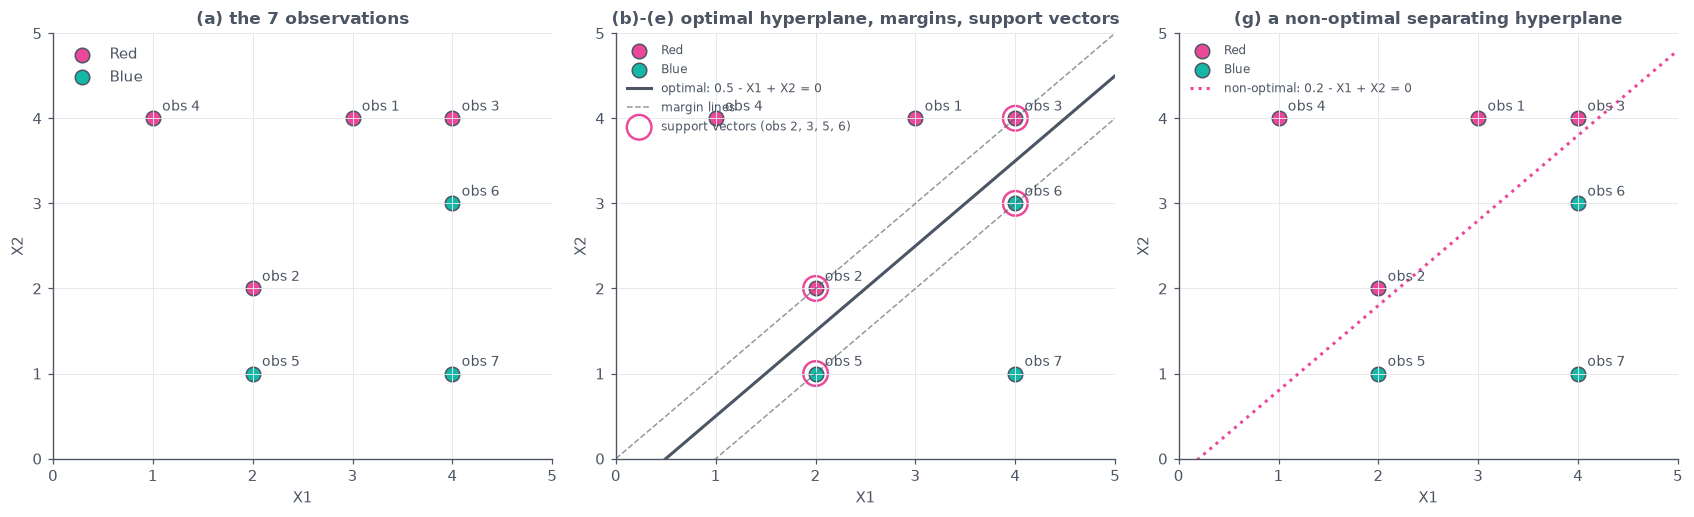

In [118]:
# islr 9.7.3 data and the sketch for parts (a)-(g)
X9 = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]],
              dtype=float)
y9 = np.array([1, 1, 1, 1, 0, 0, 0])  # 1 = red (pink), 0 = blue (teal)
labels9 = [f"obs {i + 1}" for i in range(7)]


def draw_points(ax):
    # scatter the 7 observations with labels
    ax.scatter(X9[y9 == 1, 0], X9[y9 == 1, 1], color=PINK, s=45, label="Red",
               edgecolor=NEUTRAL)
    ax.scatter(X9[y9 == 0, 0], X9[y9 == 0, 1], color=TEAL, s=45, label="Blue",
               edgecolor=NEUTRAL)
    for i, (x, y_) in enumerate(X9):
        ax.annotate(labels9[i], (x, y_), textcoords="offset points",
                    xytext=(5, 4), color=NEUTRAL, fontsize=7)
    ax.set_xlim(0, 5)
    ax.set_ylim(0, 5)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")


fig, axes = plt.subplots(1, 3, figsize=(6.2, 2.1))

# (a) sketch of the observations
draw_points(axes[0])
axes[0].set_title("(a) the 7 observations", fontsize=7)
axes[0].legend(loc="upper left", fontsize=5)

# (b)-(e) optimal hyperplane x2 = x1 - 0.5, margin lines, support vectors
draw_points(axes[1])
xx = np.linspace(0, 5, 100)
axes[1].plot(xx, xx - 0.5, color=NEUTRAL, lw=1.8,
             label="optimal: 0.5 - X1 + X2 = 0")
axes[1].plot(xx, xx, color=NEUTRAL, lw=0.8, linestyle="--", alpha=0.6,
             label="margin lines")
axes[1].plot(xx, xx - 1, color=NEUTRAL, lw=0.8, linestyle="--", alpha=0.6)
axes[1].scatter(X9[[1, 2, 4, 5], 0], X9[[1, 2, 4, 5], 1], s=130,
                facecolors="none", edgecolors=PINK, linewidths=1.2,
                label="support vectors (obs 2, 3, 5, 6)")
axes[1].set_title("(b)-(e) hyperplane, margins, SVs", fontsize=7)
axes[1].legend(loc="upper left", fontsize=4.5)

# (g) a non-optimal separating hyperplane
draw_points(axes[2])
axes[2].plot(xx, xx - 0.2, color=PINK, lw=1.5, linestyle=":",
             label="non-optimal: 0.2 - X1 + X2 = 0")
axes[2].set_title("(g) non-optimal hyperplane", fontsize=7)
axes[2].legend(loc="upper left", fontsize=4.5)

plt.tight_layout()
plt.show()

**(a)** The sketch is the left panel above: Red (pink) at $(3,4)$, $(2,2)$, $(4,4)$, $(1,4)$; Blue (teal) at $(2,1)$, $(4,3)$, $(4,1)$.

**(b)** Optimal separating hyperplane: $0.5 - X_1 + X_2 = 0$ (i.e. $X_2 = X_1 - 0.5$). Every Red point gives $0.5 - X_1 + X_2 > 0$ (1.5, 0.5, 0.5, 3.5) and every Blue gives $< 0$ ($-0.5$, $-0.5$, $-2.5$), so it separates the classes; among separating lines its margin is maximal — the closest points on both sides (obs 2, 3, 5, 6) are exactly equidistant from it, verified numerically with `SVC(kernel="linear", C=1e6)` below.

**(c)** Classify to Red if $\beta_0 + \beta_1 X_1 + \beta_2 X_2 > 0$, else Blue, with **$\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$**: Red lies above the line $X_2 = X_1 - 0.5$, Blue below it.

**(d)** Margin = distance to the closest observation $= \frac{|0.5 - X_1 + X_2|}{\sqrt{(-1)^2 + 1^2}} = \frac{0.5}{\sqrt{2}} = \frac{\sqrt{2}}{4} \approx 0.354$ (obs 2, 3, 5, 6 each give $|0.5|$), confirmed numerically below.

**(e)** Support vectors: **observations 2, 3, 5, 6** (circled in the middle panel) — the four points exactly on the margin lines $0.5 - X_1 + X_2 = \pm 0.5$; they alone determine the hyperplane, and `SVC` returns exactly these four.

**(f)** **Observation 7** is *not* a support vector (distance $|0.5 - 4 + 1|/\sqrt{2} = 2.5/\sqrt{2} \gg 0.354$), so slightly moving it does **not** change the maximum-margin hyperplane, as long as it stays on its side of the margin line.

**(g)** Yes: the right panel draws $0.2 - X_1 + X_2 = 0$ (i.e. $X_2 = X_1 - 0.2$), which separates all seven points with a smaller margin — its nearest points are obs 2 and 3, at $0.2/\sqrt{2} \approx 0.141 < 0.354$ (obs 5 and 6 sit farther, at $0.8/\sqrt{2} \approx 0.566$).

**(h)** Adding a Blue point at $(2,3)$ makes the classes **not separable**: it evaluates to $0.5 - 2 + 3 = 1.5 > 0$, on the Red side of the optimal hyperplane (in fact of *any* separating line through this point cloud), yet it is Blue.


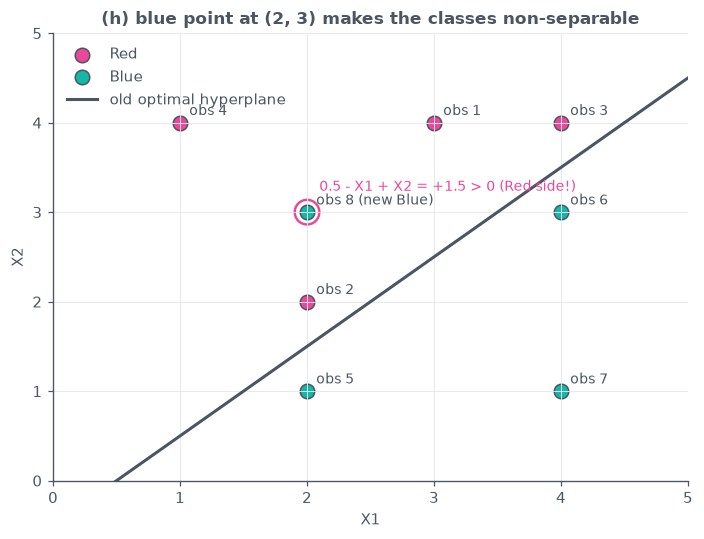

In [122]:
# (h) plot with the extra blue point that makes the classes non-separable
X8 = np.vstack([X9, [2, 3]])
y8 = np.append(y9, 0)

fig, ax = plt.subplots(figsize=(4.4, 3.4))
ax.scatter(X8[y8 == 1, 0], X8[y8 == 1, 1], color=PINK, s=90, label="Red",
           edgecolor=NEUTRAL)
ax.scatter(X8[y8 == 0, 0], X8[y8 == 0, 1], color=TEAL, s=90, label="Blue",
           edgecolor=NEUTRAL)
xx = np.linspace(0, 5, 100)
ax.plot(xx, xx - 0.5, color=NEUTRAL, lw=2, label="old optimal hyperplane")
for i, (x, y_) in enumerate(X8):
    tag = labels9[i] if i < 7 else "obs 8 (new Blue)"
    ax.annotate(tag, (x, y_), textcoords="offset points", xytext=(6, 5),
                color=NEUTRAL, fontsize=7)
ax.scatter([2], [3], s=260, facecolors="none", edgecolors=PINK, linewidths=1.6)
ax.annotate("0.5 - X1 + X2 = +1.5 > 0 (Red side!)", (2, 3),
            textcoords="offset points", xytext=(8, 14), color=PINK, fontsize=7)
ax.set_xlim(0, 5)
ax.set_ylim(0, 5)
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_title("(h) blue point at (2, 3) makes the classes non-separable")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [120]:
# numeric verification of (b), (d), (e) with a hard-margin linear svm
svc = SVC(kernel="linear", C=1e6)
svc.fit(X9, y9)

w = svc.coef_[0]
b = svc.intercept_[0]
scale = -1.0 / w[0]  # renormalize so the x1 coefficient is -1
print(f"raw svm: coef = {w}, intercept = {b:.6f}")
print(f"renormalized hyperplane: {scale * b:.4f} - X1 + {scale * w[1]:.4f} X2 = 0")
print(f"support vectors: {[labels9[i] for i in svc.support_]}")
print(f"margin (distance hyperplane -> nearest support vector) = "
      f"{1 / np.linalg.norm(w):.4f} (sqrt(2)/4 = {np.sqrt(2) / 4:.4f})")

# distances of every observation to the hyperplane
dists = np.abs(b + X9 @ w) / np.linalg.norm(w)
for name, d, cls in zip(labels9, dists, y9):
    print(f"{name}: distance = {d:.4f} ({'red' if cls == 1 else 'blue'})")


raw svm: coef = [-1.99941406  1.99941406], intercept = 0.999707
renormalized hyperplane: 0.5000 - X1 + 1.0000 X2 = 0
support vectors: ['obs 5', 'obs 6', 'obs 2', 'obs 3']
margin (distance hyperplane -> nearest support vector) = 0.3537 (sqrt(2)/4 = 0.3536)
obs 1: distance = 1.0607 (red)
obs 2: distance = 0.3536 (red)
obs 3: distance = 0.3536 (red)
obs 4: distance = 2.4749 (red)
obs 5: distance = 0.3536 (blue)
obs 6: distance = 0.3536 (blue)
obs 7: distance = 1.7678 (blue)


The hard-margin SVM (`SVC(kernel="linear", C=1e6)`) recovers $0.5 - X_1 + X_2 = 0$ with support vectors obs 2, 3, 5, 6 and margin 0.3537 ≈ $\sqrt{2}/4$, matching the hand answers; observation 7 sits at distance 1.7678, far outside the margin, confirming (f).


## References

1. UCI ML Repository - *APS Failure at Scania Trucks Data Set*: https://archive.ics.uci.edu/ml/datasets/APS+Failure+at+Scania+Trucks (downloaded 2026-11-03).
2. `data/aps_failure/aps_failure_description.txt` - IDA 2016 challenge cost metric (Cost_1 = 10, Cost_2 = 500).
3. G. James, D. Witten, T. Hastie, R. Tibshirani, *An Introduction to Statistical Learning*, Springer, 2013 - p. 129; Ch. 6 (shrinkage), 8 (8.4.5), 9 (9.7.3).
4. scikit-learn documentation - `RandomForestClassifier` (OOB errors, `class_weight`), model selection (`StratifiedKFold`, `cross_val_score`, `cross_val_predict`), metrics: https://scikit-learn.org/stable/
5. C. Chen, A. Liaw, L. Breiman, *Using Random Forest to Learn Imbalanced Data*, UC Berkeley Tech. Rep. 666, 2004.
6. imbalanced-learn documentation - `SMOTE` (N. V. Chawla et al., JAIR 16:321-357, 2002), `BalancedRandomForestClassifier`: https://imbalanced-learn.org/stable/
7. T. Chen, C. Guestrin, *XGBoost: A Scalable Tree Boosting System*, KDD 2016; XGBoost docs (`reg_alpha`, `booster`, `tree_method`, `objective`): https://xgboost.readthedocs.io/
8. S. van Buuren, *Flexible Imputation of Missing Data*, 2nd ed., CRC Press, 2018; scikit-learn `IterativeImputer` / `MissingIndicator` docs.
9. pandas documentation (`read_csv` with `na_values`, `DataFrame.corr`, `fillna`): https://pandas.pydata.org/docs/
